<a href="https://colab.research.google.com/github/rania-elfadili/python-IA/blob/main/TP5_Pr%C3%A9traitement_d%E2%80%99images_num%C3%A9riques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# exercice 1 :

# question 1 :

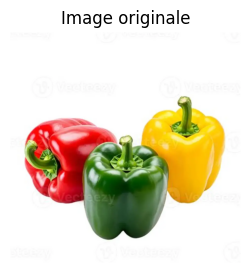

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# On charge l’image d'aprés opencv
img1 = cv2.imread('peppers.webp')

# Conversion de BGR vers RGB pour un affichage correct avec matplotlib
img2 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

# affichage de l'image
plt.figure(figsize=(3,3))
plt.imshow(img2)
plt.title("Image originale")
plt.axis('off')
plt.show()


# question 2

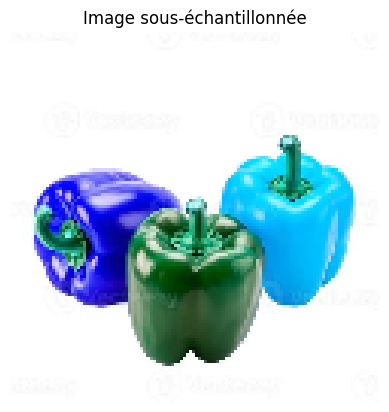

In [ ]:
# On récupère la hauteur et la largeur de l’image
h, w = img1.shape[:2]

# On définit une nouvelle taille plus petite qu'on va diviser sur 8 pour qu'il  réduit fortement le sous échantillonnage
nouvelle_taille = (w // 8, h // 8)

# on passe à la redimensionnement de l’image avec interpolation linéaire c'est une méthode simple qui fait une moyenne des pixels voisins
im2 = cv2.resize(img1, nouvelle_taille, interpolation=cv2.INTER_LINEAR)

# Affichage de l’image réduite
plt.imshow(im2)
plt.title("Image sous-échantillonnée")
plt.axis('off')
plt.show()

# question 4 :

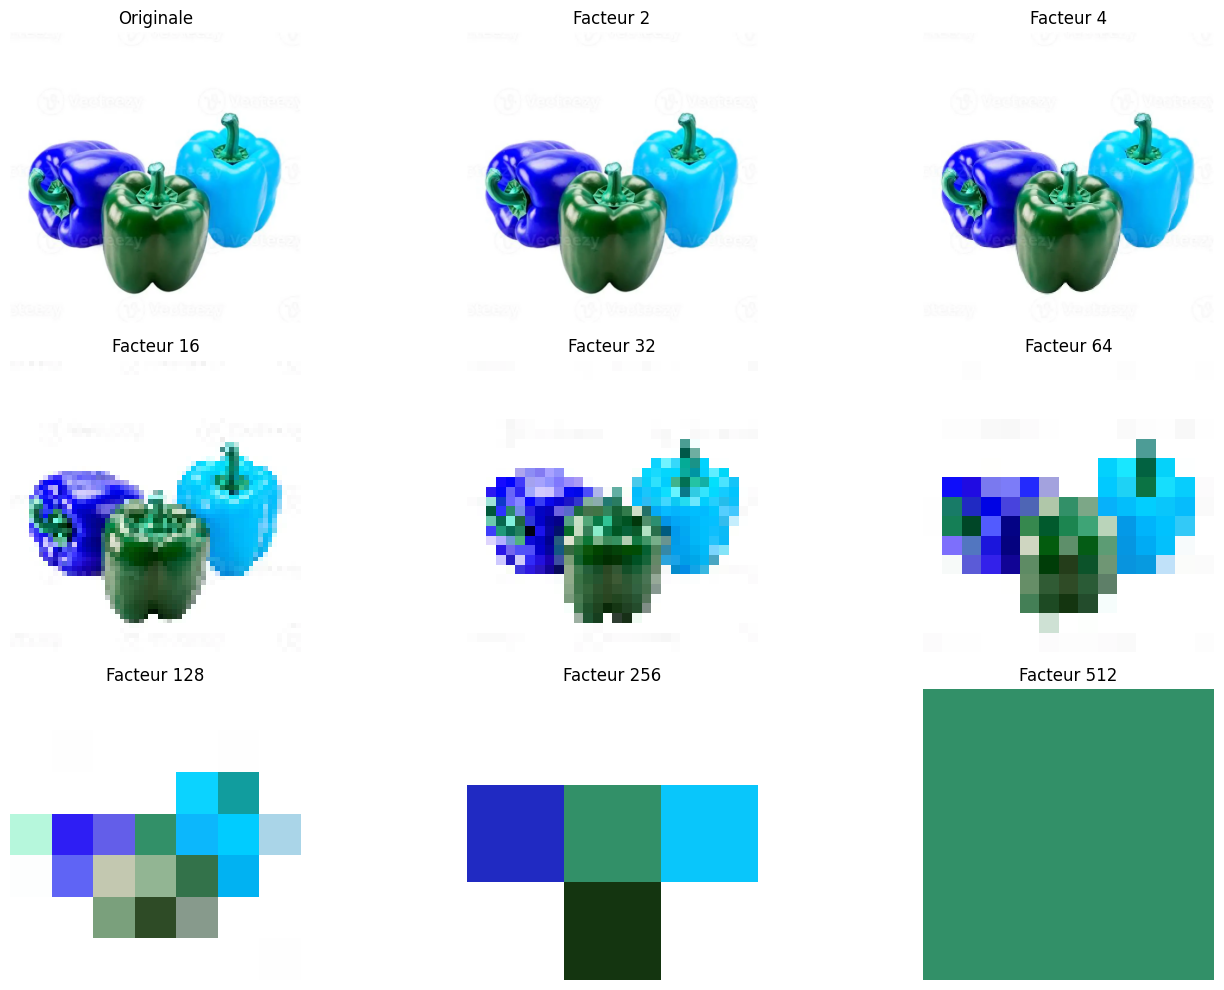

In [ ]:
# Liste des facteurs de réduction
facteurs = [2, 4, 16, 32, 64, 128, 256, 512]

# Liste pour stocker les images générées
image = []

# Boucle sur chaque facteur
for f in facteurs:
    # On calcule la nouvelle taille en divisant largeur et hauteur
    nouvelle_taille = (w // f, h // f)

    # sous-échantillonnage de l'img
    img = cv2.resize(img1, nouvelle_taille, interpolation=cv2.INTER_LINEAR)

    # On stocke le facteur et l’image
    image.append((f, img))

# Création d’une grande figure pour afficher toutes les images
plt.figure(figsize=(15, 10))

# Affichage de l’image originale
plt.subplot(3, 3, 1)
plt.imshow(img1)
plt.title("Originale")
plt.axis('off')

# Affichage des images réduites
for i, (f, img) in enumerate(image):
    # i+2 car la première case est déjà prise par l’image originale
    plt.subplot(3, 3, i + 2)

    # Affichage de l’image
    plt.imshow(img)

    # Affichage du facteur de réduction
    plt.title(f"Facteur {f}")

    # Supprimer les axes
    plt.axis('off')

# Ajustement automatique des espaces entre les images
plt.tight_layout()

# Affichage final
plt.show()


# question 6 :

In [ ]:
# Le sous-échantillonnage réduit la taille de l’image en supprimant des pixels  Cela entraîne plusieurs effets visibles comme
# perte  des détails
# L’image devient de plus en plus floue
# Les contours sont moins nets
# Quand la réduction est forte, l’image devient pixelisée

# exercice 2 :

# question 1 :

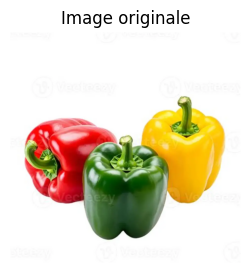

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
# Chargement  et affichage de  l'image couleur
img1 = cv2.imread('peppers.webp')
img2 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(3,3))
plt.imshow(img2)
plt.title("Image originale")
plt.axis('off')
plt.show()


# question 2 :

In [ ]:
# on définie ici une fonction qui fait la quantification d’une image
def quantification(image, niveaux):

    # Nombre total de niveaux possibles dans une image 8 bits de 0 à 255
    niveaux_max = 256

    # On calcule la taille d’un niveau
    facteur = niveaux_max // niveaux

    # On réduit les valeurs des pixels en regroupant les intensités puis on les remet sur des niveaux fixes
    img3 = (image // facteur) * facteur

    # On retourne l’image quantifiée
    return img3

# question 3 :

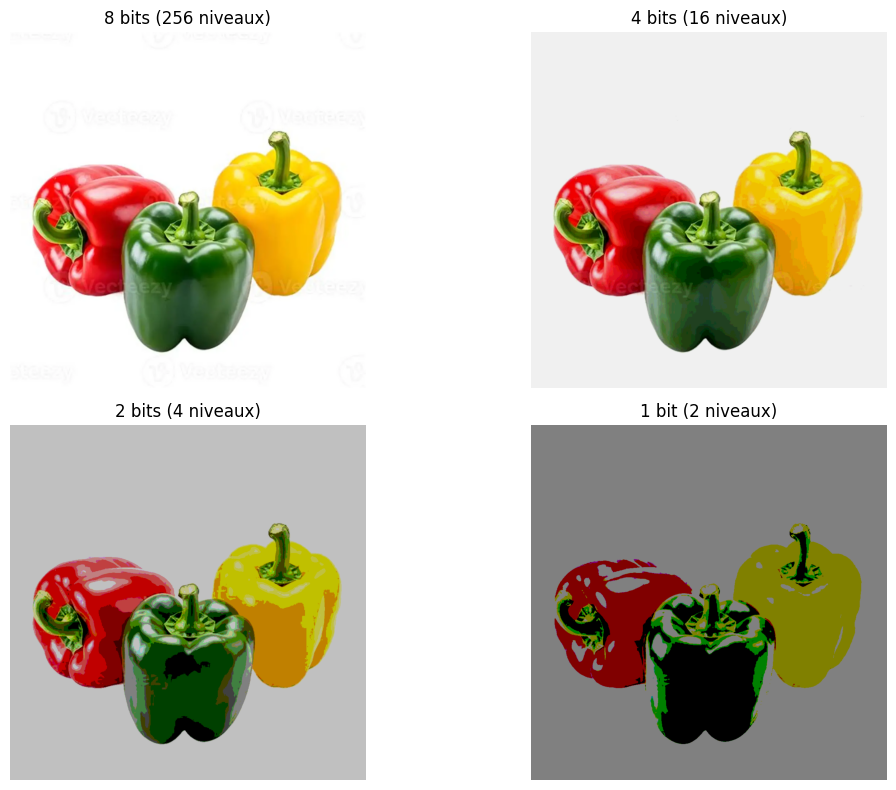

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Lecture de l’image
img1 = cv2.imread('peppers.webp')

# Conversion de BGR vers RGB pour un affichage correct
img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

# Image originale
im_8bits = img1

# Application de la quantification avec différents niveaux
im_4bits = quantification(img1, 16)  # 16 niveaux
im_2bits = quantification(img1, 4)   # 4 niveaux
im_1bit  = quantification(img1, 2)   # 2 niveaux

# Création de la figure
plt.figure(figsize=(12, 8))

# Image originale
plt.subplot(2, 2, 1)
plt.imshow(im_8bits)
plt.title("8 bits (256 niveaux)")
plt.axis('off')

# Image 4 bits
plt.subplot(2, 2, 2)
plt.imshow(im_4bits)
plt.title("4 bits (16 niveaux)")
plt.axis('off')

# Image 2 bits
plt.subplot(2, 2, 3)
plt.imshow(im_2bits)
plt.title("2 bits (4 niveaux)")
plt.axis('off')

# Image 1 bit
plt.subplot(2, 2, 4)
plt.imshow(im_1bit)
plt.title("1 bit (2 niveaux)")
plt.axis('off')

# Ajustement propre des espaces
plt.tight_layout()

# Affichage final
plt.show()

# question 4  :

In [ ]:
# Quand on réduit les niveaux de quantification on peut avoir que
# L’image perd des détails et des couleurs
# Les dégradés deviennent visibles par bandes
# L’image devient plus simple et moins précise
# Avec très peu de bits, elle devient presque noir et blanc

# question 5 :

In [ ]:
# Le nombre de bits par pixel influence la qualité de l’image
# Plus de bits == meilleure qualité mais fichier plus lourd
# Moins de bits == image plus légère mais moins précise

# exercice 3 :

# partie 1 : Modifier le contraste de l'image

# question 1 :

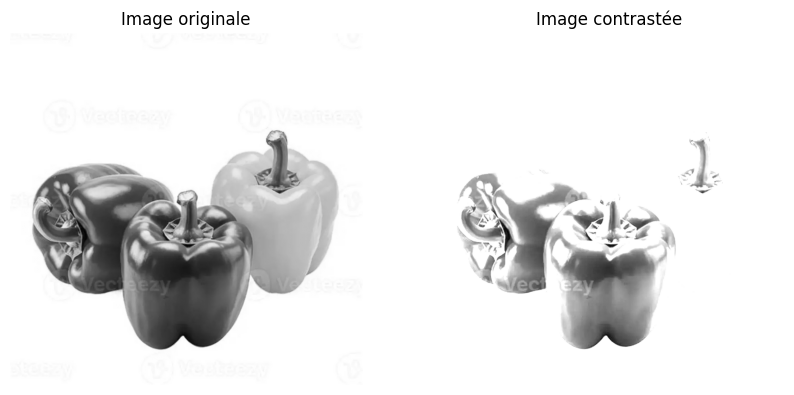

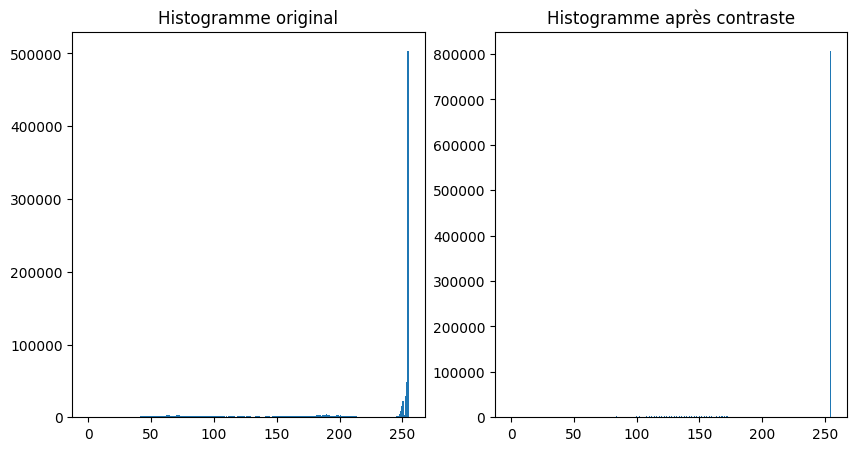

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Charger l’image en niveaux de gris
img = cv2.imread('peppers.webp', cv2.IMREAD_GRAYSCALE)

# Paramètres pour modifier le contraste et la luminosité
alpha = 2  # augmente le contraste
beta = 0    # pas de changement de luminosité

# Application de la transformation
img_contrast = cv2.convertScaleAbs(img, alpha=alpha, beta=beta)

# Affichage des images
plt.figure(figsize=(10,5))

# Image originale
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title("Image originale")
plt.axis('off')

# Image avec contraste modifié
plt.subplot(1,2,2)
plt.imshow(img_contrast, cmap='gray')
plt.title("Image contrastée")
plt.axis('off')

plt.show()

# Histogrammes pour analyser la différence
plt.figure(figsize=(10,5))

# Histogramme image originale
plt.subplot(1,2,1)
plt.hist(img.ravel(), bins=256)
plt.title("Histogramme original")

# Histogramme image contrastée
plt.subplot(1,2,2)
plt.hist(img_contrast.ravel(), bins=256)
plt.title("Histogramme après contraste")

plt.show()

# question 2 :

In [ ]:
# alpha modifie le contraste lorsque on a :
# alpha grande donc image plus contrastée, histogramme plus étalé
# alpha petite donc image moins contrastée, histogramme regroupé
# beta modifie la luminosité si on a
# beta grande  donc image plus claire, histogramme vers la droite
# beta petite donc image plus sombre, histogramme vers la gauche
# Donc alpha agit sur le contraste et beta sur la luminosité

# Partie 2 : Étirement "normalisation"

# question 1 :

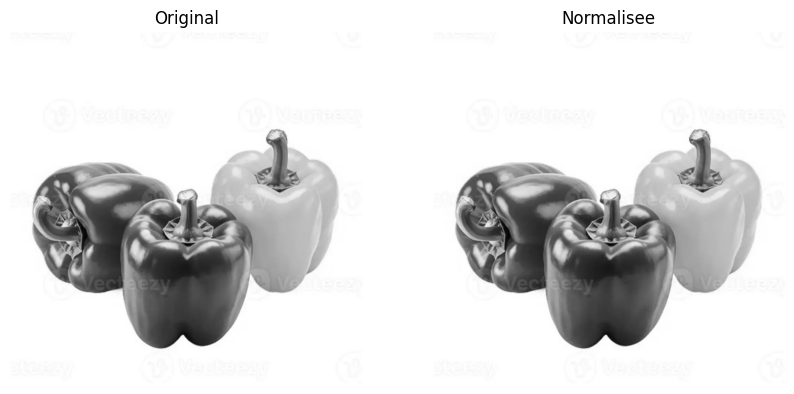

In [ ]:
import matplotlib.pyplot as plt
import cv2

# Lecture de l’image en niveaux de gris
img = cv2.imread('peppers.webp', 0)

# Normalisation de l’image entre 0 et 255
img_norm = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)

# Création de la figure
plt.figure(figsize=(10,5))

# Image originale
plt.subplot(1,2,1)
plt.title("Original")
plt.imshow(img, cmap='gray')
plt.axis('off')

# Image normalisée
plt.subplot(1,2,2)
plt.title("Normalisee")
plt.imshow(img_norm, cmap='gray')
plt.axis('off')

# Affichage final
plt.show()

# question 2  :

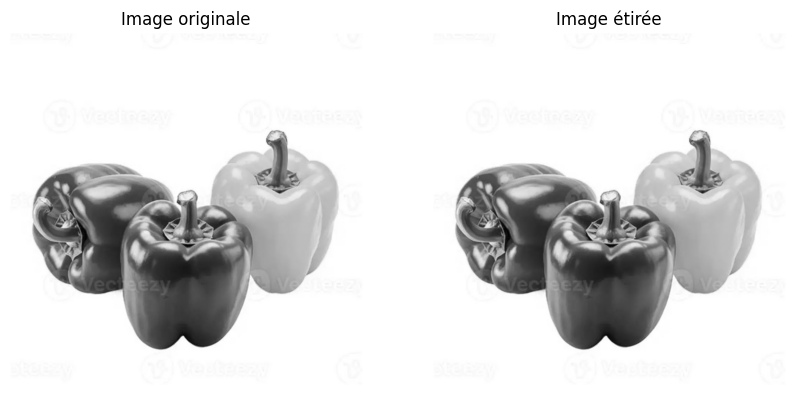

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Lecture de l'image
img = cv2.imread('peppers.webp', 0).astype(np.float32) # convertit les pixels en float utile pour éviter les erreurs lors des calculs

# Min et Max
Imin = np.min(img)
Imax = np.max(img)

# Étirement
img_stretch = (img - Imin) * 255 / (Imax - Imin) # On étire les niveaux de gris pour utiliser toute la plage [0,255]

img_stretch = img_stretch.astype(np.uint8) # Convertit en entiers 8 bits (0 → 255) nécessaire pour afficher correctement avec OpenCV / matplotlib

# Affichage
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.title("Image originale")
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(1,2,2)
plt.title("Image étirée")
plt.imshow(img_stretch, cmap='gray')
plt.axis('off')

plt.show()

# partie 3 :

# question 1 :

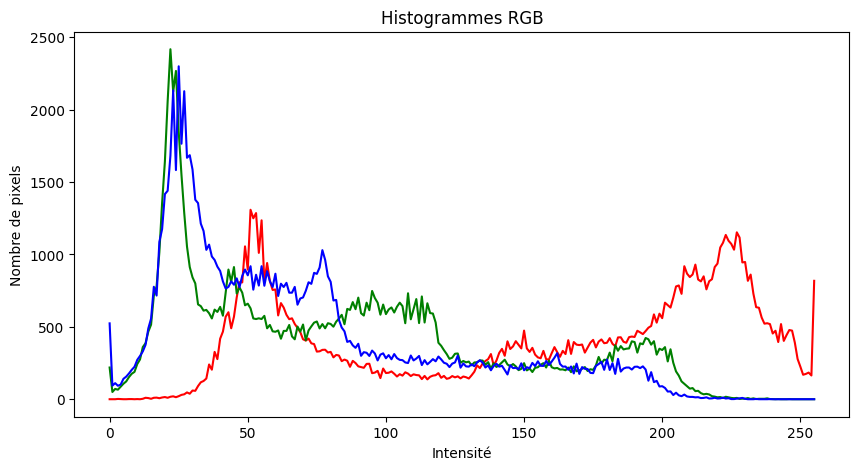

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Lire image couleur
img = cv2.imread('lena.webp')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Séparer les canaux
R = img_rgb[:,:,0]
G = img_rgb[:,:,1]
B = img_rgb[:,:,2]

# Calcul histogrammes avec OpenCV
hist_R = cv2.calcHist([img_rgb], [0], None, [256], [0,256])
hist_G = cv2.calcHist([img_rgb], [1], None, [256], [0,256])
hist_B = cv2.calcHist([img_rgb], [2], None, [256], [0,256])

# Affichage
plt.figure(figsize=(10,5))
plt.plot(hist_R, color='red')
plt.plot(hist_G, color='green')
plt.plot(hist_B, color='blue')
plt.title("Histogrammes RGB")
plt.xlabel("Intensité")
plt.ylabel("Nombre de pixels")
plt.show()

# question 2 :

In [ ]:
pic_R = np.argmax(hist_R)
pic_G = np.argmax(hist_G)
pic_B = np.argmax(hist_B)

print("Pic Rouge :", pic_R)
print("Pic Vert  :", pic_G)
print("Pic Bleu  :", pic_B)

# Le pic = valeur la plus fréquente donc Il indique la couleur dominante ou la luminosité principale de l’image

Pic Rouge : 51
Pic Vert  : 22
Pic Bleu  : 25


# question 3 :

In [ ]:
# l'objectif est d'améliorer le contraste de l’image et on redistribue les pixels pour obtenir un histogramme plus uniforme

# question 4 :

In [ ]:
# Séparer canaux (BGR ici)
B, G, R = cv2.split(img)

# Égalisation
B_eq = cv2.equalizeHist(B)
G_eq = cv2.equalizeHist(G)
R_eq = cv2.equalizeHist(R)

# Fusion
img_eq = cv2.merge([B_eq, G_eq, R_eq])
img_eq_rgb = cv2.cvtColor(img_eq, cv2.COLOR_BGR2RGB)

# question 5 :

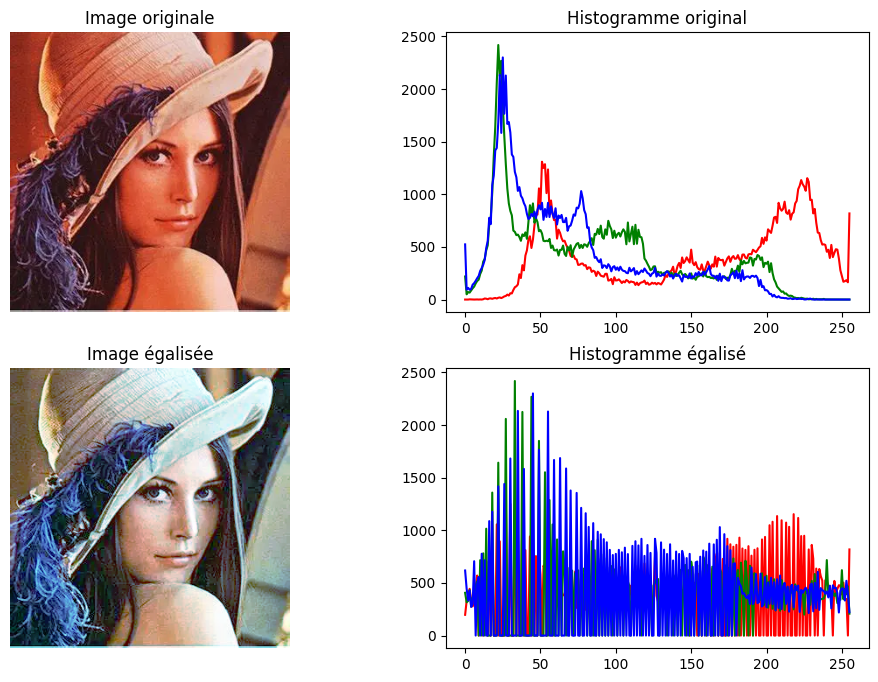

In [ ]:
plt.figure(figsize=(12,8))

# Image originale
plt.subplot(2,2,1)
plt.title("Image originale")
plt.imshow(img_rgb)
plt.axis('off')

# Histogramme original
plt.subplot(2,2,2)
plt.title("Histogramme original")
plt.plot(hist_R, color='red')
plt.plot(hist_G, color='green')
plt.plot(hist_B, color='blue')

# Image égalisée
plt.subplot(2,2,3)
plt.title("Image égalisée")
plt.imshow(img_eq_rgb)
plt.axis('off')

# Histogramme égalisé
hist_R_eq = cv2.calcHist([img_eq_rgb], [0], None, [256], [0,256])
hist_G_eq = cv2.calcHist([img_eq_rgb], [1], None, [256], [0,256])
hist_B_eq = cv2.calcHist([img_eq_rgb], [2], None, [256], [0,256])

plt.subplot(2,2,4)
plt.title("Histogramme égalisé")
plt.plot(hist_R_eq, color='red')
plt.plot(hist_G_eq, color='green')
plt.plot(hist_B_eq, color='blue')

plt.show()

# question 6 :

In [ ]:
# L’image devient plus contrastée après égalisation et les zones sombres et claires sont mieux réparties et ’histogramme devient plus étalé et équilibré

# donc on peut dire que l’égalisation d’histogramme améliore le contraste en redistribuant les niveaux de couleur pour mieux utiliser toute la plage d’intensité